In [ ]:
#Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Loading CSV file
df = pd.read_csv("/data/raw_data.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
# Storing original dataset before cleaning
df_before = df.copy(deep=True)

print("Original dataset saved successfully!")
print("Original shape:", df_before.shape)
print("Original missing values:", df_before.isnull().sum().sum())
print("Original duplicate rows:", df_before.duplicated().sum())

Original dataset saved successfully!
Original shape: (10020, 16)
Original missing values: 1508
Original duplicate rows: 20


In [ ]:
#Checking the first 5 records to confirm the data has loaded successfully
df.head()

,Customer ID,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Device Used Most Often,Genre Preference,Region,Payment History (On-Time/Delayed),Subscription Plan,Churn Status (Yes/No),Support Queries Logged,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created
0,CUST109419,62,8.0,1.45,2.0,Smartphone,Comedy,North America,Delayed,Standard,No,1.0,41,22495.0,0,2
1,CUST108768,54,NaN,5.10,7.0,Laptop,Thriller,North America,on-time,Basic,No,0.0,30,70506.0,2,1
2,CUST107656,25,6.0,3.78,6.0,Tablet,Sci-Fi,North America,On-Time,Standard,No,1.0,24,67448.0,2,4
3,CUST100416,31,8.0,2.28,3.0,Tablet,Drama,Latin America,On-Time,Basic,No,1.0,48,NaN,0,3
4,CUST103710,19,5.0,2.84,5.0,SMARTPHONE,Drama,Asia-Pacific,On-Time,Basic,No,2.0,41,31250.0,0,1


In [ ]:
#Checking the dataset dimensions
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print("Dataset Shape:", df.shape)

Number of Rows: 10020
Number of Columns: 16
Dataset Shape: (10020, 16)


In [ ]:
#Getting the structural information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10020 entries, 0 to 10019
Data columns (total 16 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Customer ID                         10020 non-null  object 
 1   Subscription Length (Months)        10020 non-null  int64  
 2   Customer Satisfaction Score (1-10)  9774 non-null   float64
 3   Daily Watch Time (Hours)            9819 non-null   float64
 4   Engagement Rate (1-10)              9820 non-null   float64
 5   Device Used Most Often              9900 non-null   object 
 6   Genre Preference                    9900 non-null   object 
 7   Region                              9920 non-null   object 
 8   Payment History (On-Time/Delayed)   9869 non-null   object 
 9   Subscription Plan                   10020 non-null  object 
 10  Churn Status (Yes/No)               10020 non-null  object 
 11  Support Queries Logged              9900 

In [ ]:
#Statistical Overview
#This will help us identify suspicious values such as unusual minimums/maximums.
df.describe()

,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Support Queries Logged,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created
count,10020.000000,9774.000000,9819.000000,9820.000000,9900.000000,10020.000000,9770.000000,10020.000000,10020.000000
mean,36.539022,6.979231,2.096288,4.132892,1.501515,36.169361,76735.484237,2.006487,3.010080
std,20.990132,1.786370,1.512098,1.974674,1.316051,10.729121,48260.806055,1.429816,1.432027
min,-3.000000,0.000000,-1.500000,0.000000,-2.000000,12.000000,-5000.000000,-1.000000,0.000000
25%,18.000000,6.000000,1.000000,3.000000,1.000000,29.000000,45013.500000,1.000000,2.000000
50%,36.000000,7.000000,1.750000,4.000000,1.000000,36.000000,65227.500000,2.000000,3.000000
75%,55.000000,8.000000,2.820000,5.000000,2.000000,43.000000,95080.250000,3.000000,4.000000
max,120.000000,15.000000,12.000000,14.000000,20.000000,105.000000,750000.000000,9.000000,10.000000


In [ ]:
#Create our initial data-quality report
quality_report = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing (%)": (df.isnull().sum() / len(df) * 100).round(2),
    "Unique Values": df.nunique()
})

quality_report

,Data Type,Missing Values,Missing (%),Unique Values
Customer ID,object,0,0.00,9901
Subscription Length (Months),int64,0,0.00,76
Customer Satisfaction Score (1-10),float64,246,2.46,13
Daily Watch Time (Hours),float64,201,2.01,697
Engagement Rate (1-10),float64,200,2.00,13
Device Used Most Often,object,120,1.20,14
Genre Preference,object,120,1.20,19
Region,object,100,1.00,15
Payment History (On-Time/Delayed),object,151,1.51,7
Subscription Plan,object,0,0.00,9


In [ ]:
#Checking duplicate rows
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)
print("Percentage of duplicate rows:",
      round((duplicate_count / len(df)) * 100, 2), "%")

Number of duplicate rows: 20
Percentage of duplicate rows: 0.2 %


In [ ]:
#Inspecting the duplicate records
duplicates = df[df.duplicated(keep=False)].sort_values("Customer ID")
duplicates

,Customer ID,Subscription Length (Months),Customer Satisfaction Score (1-10),Daily Watch Time (Hours),Engagement Rate (1-10),Device Used Most Often,Genre Preference,Region,Payment History (On-Time/Delayed),Subscription Plan,Churn Status (Yes/No),Support Queries Logged,Age,Monthly Income ($),Promotional Offers Used,Number of Profiles Created
9747,CUST100321,68,6.0,4.42,7.0,Laptop,Action,North America,On-Time,Premium,No,0.0,34,53668.0,4,5
227,CUST100321,68,6.0,4.42,7.0,Laptop,Action,North America,On-Time,Premium,No,0.0,34,53668.0,4,5
3712,CUST102024,40,7.0,1.61,3.0,Laptop,Sci-Fi,North America,On-Time,Basic,No,1.0,21,83666.0,2,2
8591,CUST102024,40,7.0,1.61,3.0,Laptop,Sci-Fi,North America,On-Time,Basic,No,1.0,21,83666.0,2,2
9785,CUST102049,56,5.0,1.22,2.0,Smartphone,Action,Asia-Pacific,delayed,Standard,Yes,1.0,24,70608.0,3,5
9324,CUST102049,56,5.0,1.22,2.0,Smartphone,Action,Asia-Pacific,delayed,Standard,Yes,1.0,24,70608.0,3,5
8562,CUST102070,37,6.0,0.18,2.0,Smart TV,Documentary,Europe,Delayed,Basic,Yes,2.0,32,44595.0,2,5
6832,CUST102070,37,6.0,0.18,2.0,Smart TV,Documentary,Europe,Delayed,Basic,Yes,2.0,32,44595.0,2,5
7788,CUST102092,21,7.0,0.05,4.0,Smartphone,Thriller,North America,On-Time,Premium,No,2.0,37,47919.0,3,1
6549,CUST102092,21,7.0,0.05,4.0,Smartphone,Thriller,North America,On-Time,Premium,No,2.0,37,47919.0,3,1


In [ ]:
#Removing the duplicate records
df_clean = df.drop_duplicates().copy()
print("Rows before removing duplicates:", len(df))
print("Rows after removing duplicates:", len(df_clean))
print("Duplicate rows removed:", len(df) - len(df_clean))

Rows before removing duplicates: 10020
Rows after removing duplicates: 10000
Duplicate rows removed: 20


In [ ]:
# Keeping only the first record for each Customer ID
df_clean = df_clean.drop_duplicates(
    subset=["Customer ID"],
    keep="first"
).copy()

print("Rows after removing repeated Customer IDs:", len(df_clean))
print("Unique Customer IDs:", df_clean["Customer ID"].nunique())
print("Duplicate Customer IDs remaining:",df_clean["Customer ID"].duplicated().sum())

Rows after removing repeated Customer IDs: 9901
Unique Customer IDs: 9901
Duplicate Customer IDs remaining: 0


In [ ]:
#Validating that duplicates rows are deleted
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("Unique Customer IDs:", df_clean["Customer ID"].nunique())
print("Total rows:", len(df_clean))

Duplicate rows after cleaning: 0
Unique Customer IDs: 9901
Total rows: 9901


In [ ]:
#Getting the exact missing value count
missing = df_clean.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing

,0
Monthly Income ($),247
Customer Satisfaction Score (1-10),241
Engagement Rate (1-10),198
Daily Watch Time (Hours),197
Payment History (On-Time/Delayed),147
Support Queries Logged,119
Device Used Most Often,118
Genre Preference,118
Region,100


In [ ]:
#Calculating the missing value percentage
missing_report = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing (%)": (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
})

missing_report = missing_report[
    missing_report["Missing Values"] > 0
].sort_values("Missing Values", ascending=False)

missing_report

,Missing Values,Missing (%)
Monthly Income ($),247,2.49
Customer Satisfaction Score (1-10),241,2.43
Engagement Rate (1-10),198,2.00
Daily Watch Time (Hours),197,1.99
Payment History (On-Time/Delayed),147,1.48
Support Queries Logged,119,1.20
Device Used Most Often,118,1.19
Genre Preference,118,1.19
Region,100,1.01


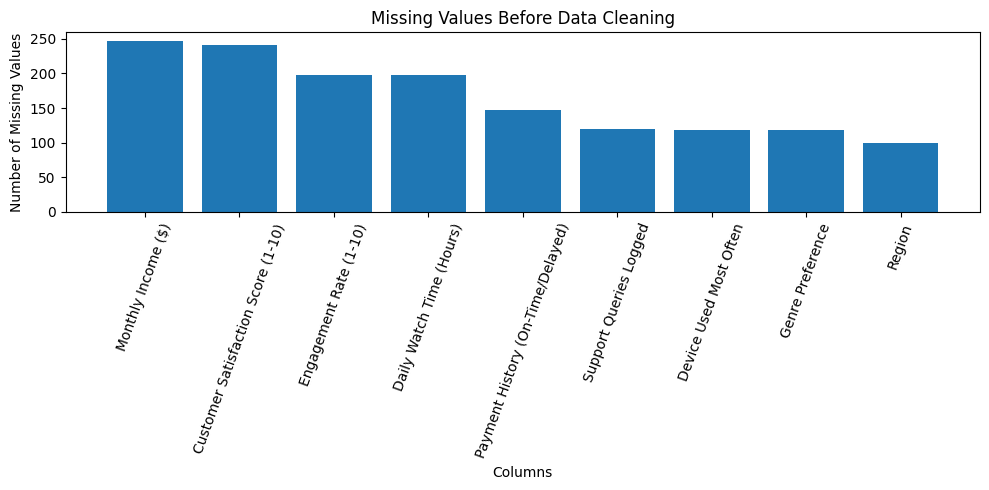

In [ ]:
#Visualizing the missing values
#This will give a before-cleaning visualization that will later be compared against the cleaned dataset.
plt.figure(figsize=(10, 5))

plt.bar(
    missing_report.index,
    missing_report["Missing Values"]
)

plt.title("Missing Values Before Data Cleaning")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=70)
plt.tight_layout()
plt.show()

In [ ]:
# Identifying columns containing missing values
missing_columns = missing_report.index.tolist()

# Separating them by data type
numerical_missing = [
    col for col in missing_columns
    if pd.api.types.is_numeric_dtype(df_clean[col])
]

categorical_missing = [
    col for col in missing_columns
    if not pd.api.types.is_numeric_dtype(df_clean[col])
]

print("Numerical columns with missing values:")
for col in numerical_missing:
    print("-", col)

print("\nCategorical columns with missing values:")
for col in categorical_missing:
    print("-", col)

Numerical columns with missing values:
- Monthly Income ($)
- Customer Satisfaction Score (1-10)
- Engagement Rate (1-10)
- Daily Watch Time (Hours)
- Support Queries Logged

Categorical columns with missing values:
- Payment History (On-Time/Delayed)
- Device Used Most Often
- Genre Preference
- Region


In [ ]:
# Comparing mean and median for numerical columns with missing values
comparison = pd.DataFrame({
    "Mean": df_clean[numerical_missing].mean(),
    "Median": df_clean[numerical_missing].median(),
    "Difference": (
        df_clean[numerical_missing].mean()
        - df_clean[numerical_missing].median()
    ).round(2)
})

comparison

,Mean,Median,Difference
Monthly Income ($),76727.271079,65227.50,11499.77
Customer Satisfaction Score (1-10),6.982195,7.00,-0.02
Engagement Rate (1-10),4.132639,4.00,0.13
Daily Watch Time (Hours),2.096924,1.75,0.35
Support Queries Logged,1.503578,1.00,0.50


In [ ]:
# Storing missing counts before imputation
missing_before = df_clean[numerical_missing].isnull().sum()

# Applying median imputation
for col in numerical_missing:
    median_value = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_value)

In [ ]:
# Displaying what was filled
imputation_summary = pd.DataFrame({
    "Missing Before": missing_before,
    "Missing After": df_clean[numerical_missing].isnull().sum(),
    "Imputation Method": "Median"
})

imputation_summary

,Missing Before,Missing After,Imputation Method
Monthly Income ($),247,0,Median
Customer Satisfaction Score (1-10),241,0,Median
Engagement Rate (1-10),198,0,Median
Daily Watch Time (Hours),197,0,Median
Support Queries Logged,119,0,Median


In [ ]:
categorical_cols = [
    "Device Used Most Often",
    "Genre Preference",
    "Region",
    "Payment History (On-Time/Delayed)",
    "Subscription Plan"
]

for col in categorical_cols:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

In [ ]:
# Examine the most frequent categories before imputation
for col in categorical_missing:
    print(df_clean[col].value_counts(dropna=False))
    print("Total: ",df_clean[col].value_counts(dropna=False).sum())
    print("\n")

Payment History (On-Time/Delayed)
on-time    7560
delayed    2106
<NA>        147
on time      88
Name: count, dtype: Int64
Total:  9901


Device Used Most Often
smart tv       3650
smartphone     3203
laptop         1893
tablet         1001
<NA>            118
smart phone      36
Name: count, dtype: Int64
Total:  9901


Genre Preference
comedy         1691
thriller       1666
documentary    1666
action         1651
sci-fi         1557
drama          1534
<NA>            118
sci fi           18
Name: count, dtype: Int64
Total:  9901


Region
north america    3349
asia-pacific     2739
europe           2466
latin america    1217
<NA>              100
asia pacific       30
Name: count, dtype: Int64
Total:  9901




In [ ]:
# Store missing counts before categorical imputation
categorical_missing_before = df_clean[categorical_missing].isnull().sum()

# Apply mode imputation
for col in categorical_missing:
    mode_value = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_value)

# Create validation summary
categorical_imputation_summary = pd.DataFrame({
    "Missing Before": categorical_missing_before,
    "Missing After": df_clean[categorical_missing].isnull().sum(),
    "Imputation Method": "Mode"
})

categorical_imputation_summary

,Missing Before,Missing After,Imputation Method
Payment History (On-Time/Delayed),147,0,Mode
Device Used Most Often,118,0,Mode
Genre Preference,118,0,Mode
Region,100,0,Mode


In [ ]:
# Final missing-value validation
remaining_missing = df_clean.isnull().sum()
print("Total missing values remaining:",
      remaining_missing.sum())
print("\nColumns with missing values:")
print(remaining_missing[remaining_missing > 0])

Total missing values remaining: 0

Columns with missing values:
Series([], dtype: int64)


In [ ]:
# Define valid ranges for numerical columns
valid_ranges = {
    "Subscription Length (Months)": (1, 72),
    "Customer Satisfaction Score (1-10)": (1, 10),
    "Daily Watch Time (Hours)": (0, 8),
    "Engagement Rate (1-10)": (1, 10),
    "Support Queries Logged": (0, 10),
    "Age": (18, 70),
    "Monthly Income ($)": (5000, 500000),
    "Promotional Offers Used": (0, 5),
    "Number of Profiles Created": (1, 6)
}

print("Valid ranges defined for", len(valid_ranges), "numerical columns.")

Valid ranges defined for 9 numerical columns.


In [ ]:
# Detect values outside the acceptable range
invalid_values = {}
for col, (minimum, maximum) in valid_ranges.items():
    mask = (df_clean[col] < minimum) | (df_clean[col] > maximum)
    invalid_values[col] = int(mask.sum())
invalid_report = pd.DataFrame({
    "Invalid Values": invalid_values
})
invalid_report = invalid_report[invalid_report["Invalid Values"] > 0]
invalid_report.sort_values("Invalid Values", ascending=False)

,Invalid Values
Subscription Length (Months),35
Customer Satisfaction Score (1-10),30
Daily Watch Time (Hours),30
Engagement Rate (1-10),29
Support Queries Logged,25
Age,25
Monthly Income ($),25
Promotional Offers Used,25
Number of Profiles Created,24


In [ ]:
# Display the actual invalid values in each numerical column
for col, (minimum, maximum) in valid_ranges.items():
    mask = (df_clean[col] < minimum) | (df_clean[col] > maximum)
    if mask.sum() > 0:
        print(f"\n{'='*60}")
        print(f"{col}")
        print(f"Valid range: {minimum} to {maximum}")
        print(f"{'='*60}")
        print(df_clean.loc[mask, ["Customer ID", col]])


Subscription Length (Months)
Valid range: 1 to 72
     Customer ID  Subscription Length (Months)
127   CUST101482                            90
144   CUST109992                            -3
802   CUST106932                             0
965   CUST106343                            90
1505  CUST108896                            90
1669  CUST105785                            -3
1978  CUST105210                            90
1984  CUST102020                             0
2227  CUST102225                            90
2250  CUST103495                            90
2300  CUST105786                           120
2715  CUST100445                            -3
2838  CUST102446                            -3
3207  CUST101359                           120
3555  CUST104140                            -3
3673  CUST107212                            90
4506  CUST101371                           120
5059  CUST109529                           120
5118  CUST107182                            -3
5460  CUS

In [ ]:
# Convert invalid numerical values to NaN
invalid_numeric_summary = {}
for col, (minimum, maximum) in valid_ranges.items():

    invalid_mask = (
        (df_clean[col] < minimum) |
        (df_clean[col] > maximum)
    )
    invalid_numeric_summary[col] = int(invalid_mask.sum())
    # Replace invalid values with NaN
    df_clean.loc[invalid_mask, col] = np.nan
invalid_numeric_report = pd.DataFrame({
    "Invalid Values Converted to NaN": invalid_numeric_summary
})
invalid_numeric_report = invalid_numeric_report[
    invalid_numeric_report["Invalid Values Converted to NaN"] > 0
]
invalid_numeric_report.sort_values(
    "Invalid Values Converted to NaN",
    ascending=False
)

,Invalid Values Converted to NaN
Subscription Length (Months),35
Customer Satisfaction Score (1-10),30
Daily Watch Time (Hours),30
Engagement Rate (1-10),29
Support Queries Logged,25
Age,25
Monthly Income ($),25
Promotional Offers Used,25
Number of Profiles Created,24


In [ ]:
# Update numerical columns
numerical_columns = [
    col for col in valid_ranges.keys()
    if col in df_clean.columns
]

# Count missing values before imputation
numeric_missing_before = df_clean[numerical_columns].isnull().sum()

# Impute missing/invalid numerical values using median
for col in numerical_columns:
    if df_clean[col].isnull().sum() > 0:
        median_value = df_clean[col].median()
        df_clean[col] = df_clean[col].fillna(median_value)

# Create validation summary
numeric_imputation_summary = pd.DataFrame({
    "Missing Before": numeric_missing_before,
    "Missing After": df_clean[numerical_columns].isnull().sum(),
    "Method": "Median"
})

numeric_imputation_summary[
    numeric_imputation_summary["Missing Before"] > 0
]

,Missing Before,Missing After,Method
Subscription Length (Months),35,0,Median
Customer Satisfaction Score (1-10),30,0,Median
Daily Watch Time (Hours),30,0,Median
Engagement Rate (1-10),29,0,Median
Support Queries Logged,25,0,Median
Age,25,0,Median
Monthly Income ($),25,0,Median
Promotional Offers Used,25,0,Median
Number of Profiles Created,24,0,Median


In [ ]:
# Validate that no invalid numerical values remain
validation_results = []
for col, (minimum, maximum) in valid_ranges.items():
    if col in df_clean.columns:
        invalid_count = (
            (df_clean[col] < minimum) |
            (df_clean[col] > maximum)
        ).sum()

        validation_results.append({
            "Column": col,
            "Allowed Range": f"{minimum} - {maximum}",
            "Invalid Values Remaining": invalid_count
        })
numerical_validation = pd.DataFrame(validation_results)
numerical_validation

,Column,Allowed Range,Invalid Values Remaining
0,Subscription Length (Months),1 - 72,0
1,Customer Satisfaction Score (1-10),1 - 10,0
2,Daily Watch Time (Hours),0 - 8,0
3,Engagement Rate (1-10),1 - 10,0
4,Support Queries Logged,0 - 10,0
5,Age,18 - 70,0
6,Monthly Income ($),5000 - 500000,0
7,Promotional Offers Used,0 - 5,0
8,Number of Profiles Created,1 - 6,0


In [ ]:

# Standardizing Genre Preference

df_clean["Genre Preference"] = (
    df_clean["Genre Preference"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "sci fi": "sci-fi",
        "science fiction": "sci-fi"
    })
)

# Checking standardized genre categories
print("Unique Genre Categories:")
print(sorted(df_clean["Genre Preference"].dropna().unique()))


Unique Genre Categories:
['action', 'comedy', 'documentary', 'drama', 'sci-fi', 'thriller']


In [ ]:

# Standardizing Churn Status

df_clean["Churn Status (Yes/No)"] = (
    df_clean["Churn Status (Yes/No)"]
    .astype("string")
    .str.strip()
    .str.upper()
    .replace({
        "Y": "YES",
        "N": "NO"
    })
)

print(df_clean["Churn Status (Yes/No)"].value_counts(dropna=False))


Churn Status (Yes/No)
NO     7432
YES    2469
Name: count, dtype: Int64


In [ ]:

# Standardizing Region Categories

df_clean["Region"] = (
    df_clean["Region"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "asia pacific": "asia-pacific",
        "north america": "north-america",
        "latin america": "latin-america"
    })
)

# Checking standardized categories
print("Unique Region Categories:")
print(sorted(df_clean["Region"].dropna().unique()))


Unique Region Categories:
['asia-pacific', 'europe', 'latin-america', 'north-america']


In [ ]:

# Standardizing Payment History

df_clean["Payment History (On-Time/Delayed)"] = (
    df_clean["Payment History (On-Time/Delayed)"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "on time": "on-time",
        "ontime": "on-time",
        "delayed ": "delayed"
    })
)

# Check standardized categories
print("Payment History Categories:")
print(
    df_clean["Payment History (On-Time/Delayed)"]
    .value_counts(dropna=False)
)


Payment History Categories:
Payment History (On-Time/Delayed)
on-time    7795
delayed    2106
Name: count, dtype: Int64


In [ ]:

# Standardizing Device Categories

df_clean["Device Used Most Often"] = (
    df_clean["Device Used Most Often"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "smart phone": "smartphone",
        "smartphone": "smartphone",
        "smart tv": "smart tv",
        "laptop": "laptop",
        "tablet": "tablet"
    })
    .str.title()
)

# Check standardized categories
print("Device Categories:")
print(df_clean["Device Used Most Often"].value_counts(dropna=False))


Device Categories:
Device Used Most Often
Smart Tv      3768
Smartphone    3239
Laptop        1893
Tablet        1001
Name: count, dtype: Int64


In [ ]:
# Final data quality validation
print("FINAL DATA QUALITY CHECK")
print("=" * 50)

print("\nDataset Shape:")
print(df_clean.shape)

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nUnique Customer IDs:")
print(df_clean["Customer ID"].nunique())

print("\nData Types:")
print(df_clean.dtypes)

FINAL DATA QUALITY CHECK

Dataset Shape:
(9901, 16)

Duplicate Rows:
0

Missing Values:
0

Unique Customer IDs:
9901

Data Types:
Customer ID                                   object
Subscription Length (Months)                 float64
Customer Satisfaction Score (1-10)           float64
Daily Watch Time (Hours)                     float64
Engagement Rate (1-10)                       float64
Device Used Most Often                string[python]
Genre Preference                      string[python]
Region                                string[python]
Payment History (On-Time/Delayed)     string[python]
Subscription Plan                     string[python]
Churn Status (Yes/No)                 string[python]
Support Queries Logged                       float64
Age                                          float64
Monthly Income ($)                           float64
Promotional Offers Used                      float64
Number of Profiles Created                   float64
dtype: object


In [ ]:
# Before vs After Data Cleaning Impact

impact_report = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Duplicate Rows",
        "Missing Values",
        "Unique Customer IDs"
    ],

    "Before Cleaning": [
        df_before.shape[0],
        df_before.shape[1],
        df_before.duplicated().sum(),
        df_before.isnull().sum().sum(),
        df_before["Customer ID"].nunique()
    ],

    "After Cleaning": [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.duplicated().sum(),
        df_clean.isnull().sum().sum(),
        df_clean["Customer ID"].nunique()
    ]
})

impact_report

,Metric,Before Cleaning,After Cleaning
0,Total Rows,10020,9901
1,Total Columns,16,16
2,Duplicate Rows,20,0
3,Missing Values,1508,0
4,Unique Customer IDs,9901,9901


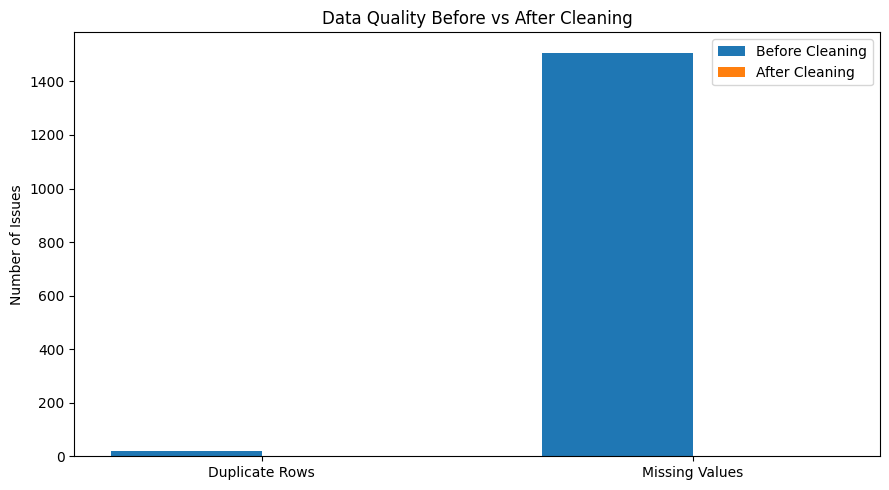

Before Cleaning: [np.int64(20), np.int64(1508)]
After Cleaning: [np.int64(0), np.int64(0)]


In [ ]:
# Visual comparison of data quality before and after cleaning

metrics = ["Duplicate Rows", "Missing Values"]

before_values = [
    impact_report.loc[
        impact_report["Metric"] == metric,
        "Before Cleaning"
    ].iloc[0]
    for metric in metrics
]

after_values = [
    impact_report.loc[
        impact_report["Metric"] == metric,
        "After Cleaning"
    ].iloc[0]
    for metric in metrics
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, before_values, width,
        label="Before Cleaning")

plt.bar(x + width/2, after_values, width,
        label="After Cleaning")

plt.xticks(x, metrics)
plt.ylabel("Number of Issues")
plt.title("Data Quality Before vs After Cleaning")
plt.legend()

plt.tight_layout()
plt.show()

print("Before Cleaning:", before_values)
print("After Cleaning:", after_values)

In [ ]:
# Export the final cleaned dataset
output_file = "/data/cleaned_data.csv"
df_clean.to_csv(output_file, index=False)
print("Cleaned dataset exported successfully!")
print("File name:", output_file)
print("Final shape:", df_clean.shape)

Cleaned dataset exported successfully!
File name: /content/drive/Shareddrives/ai/cleaned_data.csv
Final shape: (9901, 16)
